In [1]:
# imports
import simpy
import numpy as np
import sys
import pandas as pd
import os
from IPython.display import Image
from tqdm import tqdm
import matplotlib.pyplot as plt
import time
sys.path.append('../../code/pycharm')
from single_station_transient import *
from utils import *

## Transient analysis

<div dir="rtl">

### עד כה ניתחנו מערכות סטציונריות. כלומר מערכות שלא משתנות עם הזמן ומעניין אותי מה קורה בשלב שהמערכת התייצבה. בפועל זה אומר שהתפלגות זמני המתנה או מספר צרכנים במערכת לא משתנה. 
    
###  המציאות היא כזאת שמערכות משתנות עם הזמן  ולא מגיעות להתייצבות. במקרה כזה אנחנו נרצה לדעת את אורך התור או זמני המתנה כפונקציה של הזמן. 
    
### אבל איך עושים את זה? עד עכשיו ניתחנו את המערכת במצב יציב ולא כפונקציה של הזמן. 

## בעיה: במפעל מתחילים לייצר מתכות אלומיניום ברגע שהמפעל נפתח. כל מוצר עובר 3 מכונות. ב-5 דקות הראשונות הפועל עסוק באתחול מערכות למרות שפס הייצור כבר עובד. אם יצברו יותר מ-10 מוצרים  שעברו את השלב של המכונה הראשונה ויחכו למכונה הראשונה זה יגרום לבעיה - כי אין מקום פיסית בפס ייצור. במפעל רוצים דרך סימולציה לחשב את ההסתברות שיהיו יותר מ-10 מוצרים אחרי 5 דקות.  
    

###  כדי לנתח את המערכת בעזרת סימולציה, אני צריך לעשות הרבה סימולציות שמתחילות בזמן 0 ובודק מה קרה בתור בזמן 5. 
       
### תור שמתחיל עם 0 צרכנים במערכת בזמן  אשר מגיעים לפי תהליך פואסון בקצב 1. השרת משרת צרכנים בקצב 1 ומפלוג מעריכית.
    
## שאלה: מה התפלגות מספר הצרכנים אחרי 5 דקות?
    
### בשביל לעשות סימלוציה נשתמש בפונקצייה: single_sim_single_rate
    
### היא מחזיקה dictionary כאשר היא אומרת לנו כמה צרכנים היו בכל דקה עגולה. 

In [2]:
lamda = 1
mu  = 1
sim_time = 5
res  = single_sim_single_rate(lamda, mu, sim_time)
res

{0: 0, 1: 0, 2: np.int64(0), 3: np.int64(0), 4: np.int64(1), 5: np.int64(0)}

<div dir="rtl">

### על ידי סימולציה בודדת ניתן רק לראות ריאליזציה אחת. אם נרצה לדעת תכונות סטטיסטיות כמו תוחלת מספר הצרכנים ברגע 5 או ההתפלגות נצטרך לעשות הרבה סימולציות.
    
### נעשה עכשיו 5000 סימולציות ונחשב ססטיטיקות של כמה צרכנים היו בכל רגע נתון. 

In [3]:
list_of_sims = []
for ind in tqdm(range(5000)):
    list_of_sims.append(single_sim_single_rate(lamda, mu, sim_time))
    

100%|█████████████████████████████████████████████████████████████████████████████████| 5000/5000 [00:29<00:00, 168.45it/s]


<div dir="rtl">

### אני ארצה לחשב את ההתפלגות של מספר הצרכנים במערכת ברגע 5. כרגע תוצאת הסימולציה מראה לי כמה צרכנים היו בכל אחת מהסימולציות ברגע 5. אבל אני רוצה לדעת את השכיחות היחסית של מספר הצרכנים מבין כל הסימולציות. זה יקנה לי את ההתפלגות המיוחלת.
    
### בשביל לדעת שכיחות יחסית נעשה זאת בשני שלבים:
### 1. נחשב כמה פעמים היו 0, 1,2, ... צרכנים וכולי...
### 2. אחרי שחישבנו את השכיחות בסעיף 1, נחלק את הכל בסכום הכולל ונקבל את השכיחות היחסית.
    


<div dir="rtl">

##    נרצה לדעת כמה צרכנים יכולים להיות במערכת. כלומר מה המקסימום. נחשב את הערך הכי גבוה שהתקבל. 
    


In [4]:
vals_at_5 = [dict_[5] for dict_ in list_of_sims]
vals_at_5_arr = np.array(vals_at_5)

vals_at_5_arr.max()

np.int64(12)

In [5]:
max_num_customers = 15

<div dir="rtl">

### כדי לחשב את השכיחות נעשה dictionary שהמפתחות זה מספר הצרכנים במערכת והערך שלהם הוא כמה פעמים היה. בהתחלה נאתחל את הכל ב-0 ולאחר מכן נעבור על הסימולציות ונסכום עבור כל מספר צרכנים אפשרי כמה היה סה"כ.

In [6]:
time_dict_5 = np.zeros(max_num_customers)

In [7]:
list_of_sims[0]

{0: 0,
 1: np.int64(1),
 2: np.int64(0),
 3: np.int64(1),
 4: np.int64(1),
 5: np.int64(1)}

In [8]:
list_of_sims[4]

{0: 0,
 1: np.int64(1),
 2: np.int64(2),
 3: np.int64(3),
 4: np.int64(3),
 5: np.int64(2)}

In [9]:
time_analyze  = 5
for resultDictionary in list_of_sims:
    time_dict_5[resultDictionary[time_analyze]] += 1

<div dir="rtl">

#### סיימנו את חלק 1, לחשב את השכיחויות. נעבר לחשב את השכיחות היחסית. 

In [10]:
time_dict_5

array([1.241e+03, 1.148e+03, 9.350e+02, 6.930e+02, 4.530e+02, 2.610e+02,
       1.470e+02, 6.900e+01, 3.200e+01, 1.400e+01, 4.000e+00, 2.000e+00,
       1.000e+00, 0.000e+00, 0.000e+00])

In [11]:
probs = time_dict_5/time_dict_5.sum()

C:\Users\Eshel\AppData\Local\Temp\ipykernel_26436\3030333550.py:15: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax1.legend(fontsize=22)


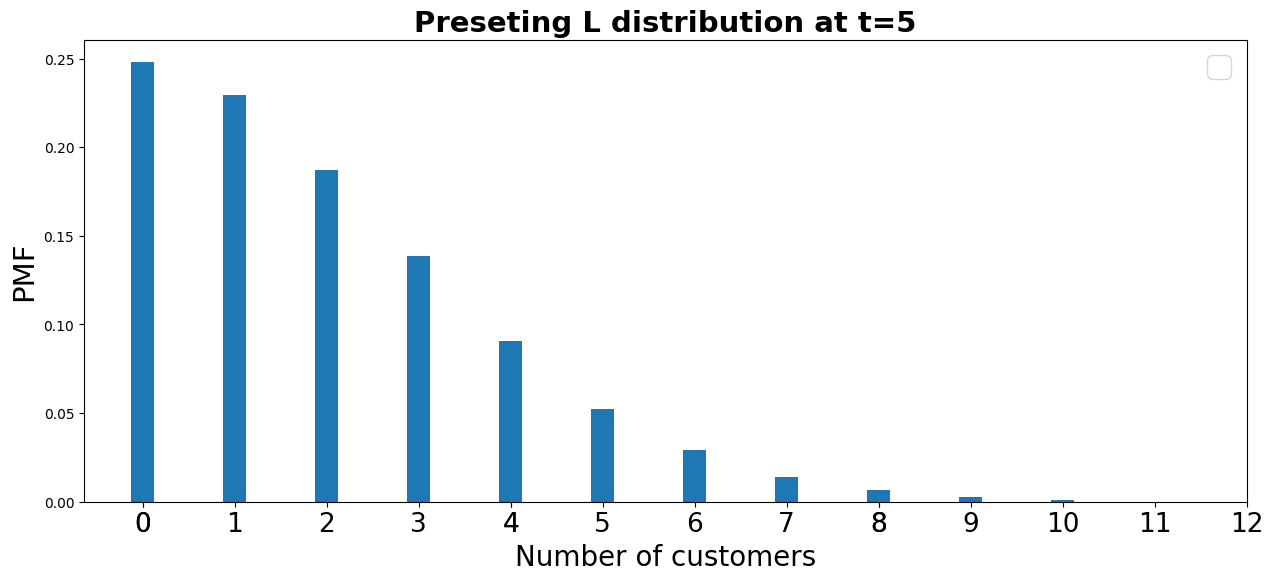

In [12]:
## Plotting the graph

fig, (ax1) = plt.subplots(1, 1, figsize=(15, 6))
width = 0.25
max_probs = 11
rects1 = ax1.bar(np.arange(max_probs),probs[:max_probs], width)
plt.rcParams['font.size'] = '20'

# # Add some text for labels, title and custom x-axis tick labels, etc.
ax1.set_ylabel('PMF', fontsize=21)
ax1.set_xlabel('Number of customers', fontsize=20)
ax1.set_title( 'Preseting L distribution at t=5' , fontsize=21, fontweight="bold")
ax1.set_xticks(np.linspace(0,12,16).astype(int))
ax1.set_xticklabels(np.linspace(0,12,16).astype(int), fontsize=19)
ax1.legend(fontsize=22)
plt.show()

In [13]:
prob_more_than_10 = probs[11:].sum()
prob_more_than_10

np.float64(0.0006000000000000001)

<div dir="rtl">

### ניתוח כפונקציה של זמן
    
#### עד כה עשינו ניתוח של רגע בודד בזמן. אבל למשל נניח שיש לנו תהליך שנרצה לזהות את הזמן שיש בו צוואר בקבוק כדי שנוכל לפעול בהתאם. 
    
## בעיה: במערכת מחשוב יש לנו ג'ובים המגיעים למערכת. כיום המערכת משרתת ג'וב אחד בשעה בממוצע. קצבי הגעה של הג'ובים משתנה לפי השעה ביום:

In [14]:
dict_sch = {0:1, 12:0.5,20:0.9}

arrival_scd_pd = convert_dict_to_pd(dict_sch)
arrival_scd_pd

,LB_time,arrival_rate
0,0.0,1.0
1,12.0,0.5
2,20.0,0.9


<div dir="rtl">

### נרצה לזהות מתי יש צוואר בקבוק במערכת במשך יממה. לפי זה הנהלה יכולה לשקול אם שווה לעבות את קצב השירות בחלקים מסוימים של היום על מנת להפחית מהעומס. 

In [15]:
rates = []
for hour in range(24):
    rates.append(give_rate_per_time(arrival_scd_pd,  hour))

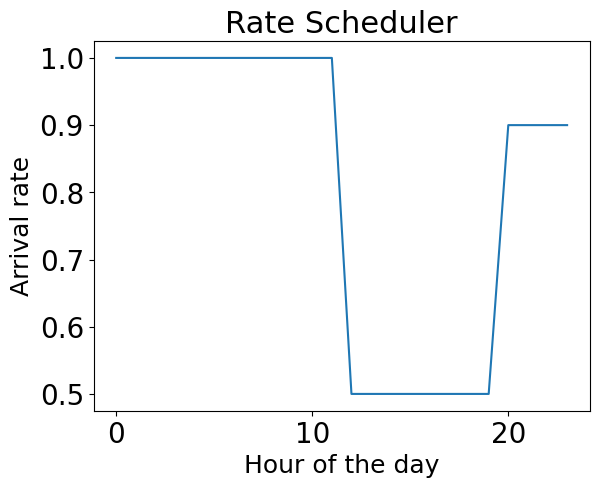

In [16]:
plt.figure()
plt.plot(np.arange(24), rates)
plt.xlabel('Hour of the day', fontsize = 18)
plt.ylabel('Arrival rate', fontsize = 18)
plt.title('Rate Scheduler', fontsize = 22)
plt.show()


<div dir="rtl">


###  פונקציית single_sim מחשבת סימלוציה בודדת של 24 שעות. מחזירה גם dictionary שמציין כמה צרכנים היו בכל שעה עגולה במערכת.
    
### בניגוד לפונקציה הקודמת קצבי הגעה יכולים להשתנות. מכניסים למערכת pandas dataframe שמציין את השעה שיש שינוי קצב ומה הקצב. למשל: 

In [17]:
dict_sch = {0:1, 12:0.5,20:0.9}
arrival_scd_pd = convert_dict_to_pd(dict_sch)
arrival_scd_pd

,LB_time,arrival_rate
0,0.0,1.0
1,12.0,0.5
2,20.0,0.9


<div dir="rtl">

### נריץ את הסימולציה הרבה פעמים:

In [18]:
dict_sch = {0:1, 12:0.5,20:0.9}
sim_time = 24 
arrival_scd_pd = convert_dict_to_pd(dict_sch)
mu = 1
sim_time = 24
list_of_sims = []
for ind in tqdm(range(10000)):
    list_of_sims.append(single_sim(arrival_scd_pd, mu, sim_time))


100%|████████████████████████████████████████████████████████████████████████████████| 10000/10000 [04:34<00:00, 36.37it/s]


<div dir="rtl">

### תוצאה של סימולציה בודדת נראית כך: 

In [19]:
list_of_sims[2]

{0: 0,
 1: np.int64(1),
 2: np.int64(0),
 3: np.int64(1),
 4: np.int64(1),
 5: np.int64(0),
 6: np.int64(0),
 7: np.int64(0),
 8: np.int64(0),
 9: np.int64(0),
 10: np.int64(3),
 11: np.int64(3),
 12: np.int64(5),
 13: np.int64(5),
 14: np.int64(5),
 15: np.int64(7),
 16: np.int64(8),
 17: np.int64(8),
 18: np.int64(7),
 19: np.int64(6),
 20: np.int64(9),
 21: np.int64(8),
 22: np.int64(11),
 23: np.int64(15),
 24: np.int64(14)}

<div dir="rtl">

### נחשב את ההתפלגות של מספר הצרכנים עבור כל שעה ביום: 

In [20]:
def compute_prob_arr(list_of_sims, max_num_customers = 100):
    time_dict = {}
    
    for hour in range(sim_time+1):
        time_dict[hour] = np.zeros(max_num_customers)
        
    for resultDictionary in list_of_sims:
        for hour in resultDictionary.keys():
            time_dict[hour][resultDictionary[hour]] += 1
            
            
        # phase 2: 
    prob_queue_arr = np.array([])

    for t in range(len(time_dict)):

        probs = (time_dict[t]/time_dict[t].sum())

        if t == 0:
            prob_queue_arr = np.array(probs).reshape(1, probs.shape[0])
        else:
            prob_queue_arr = np.concatenate((prob_queue_arr, np.array(probs).reshape(1,probs.shape[0])), axis = 0)
            
            
    return prob_queue_arr

In [21]:
list_of_sims[0]

{0: 0,
 1: np.int64(1),
 2: np.int64(1),
 3: np.int64(3),
 4: np.int64(3),
 5: np.int64(2),
 6: np.int64(1),
 7: np.int64(0),
 8: np.int64(0),
 9: np.int64(0),
 10: np.int64(0),
 11: np.int64(1),
 12: np.int64(0),
 13: np.int64(0),
 14: np.int64(0),
 15: np.int64(0),
 16: np.int64(1),
 17: np.int64(0),
 18: np.int64(0),
 19: np.int64(0),
 20: np.int64(0),
 21: np.int64(0),
 22: np.int64(0),
 23: np.int64(0),
 24: np.int64(0)}

In [22]:
prob_queue_arr = compute_prob_arr(list_of_sims)

In [23]:
print(prob_queue_arr)

[[1.     0.     0.     ... 0.     0.     0.    ]
 [0.5208 0.311  0.1205 ... 0.     0.     0.    ]
 [0.3882 0.2903 0.18   ... 0.     0.     0.    ]
 ...
 [0.3566 0.2024 0.1324 ... 0.     0.     0.    ]
 [0.3306 0.1961 0.1436 ... 0.     0.     0.    ]
 [0.3024 0.1964 0.1426 ... 0.     0.     0.    ]]


In [24]:
prob_queue_arr.shape

(25, 100)

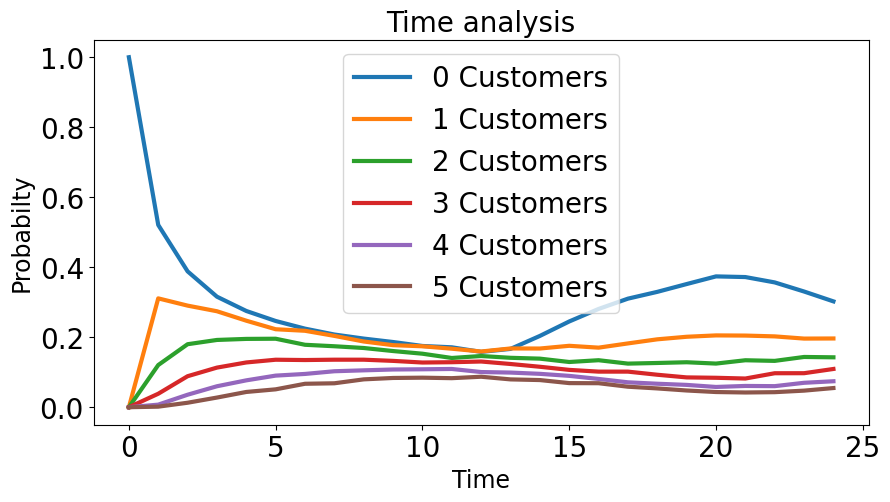

In [25]:
       
plt.figure(figsize=(10,5))
for num_cust in range(6):
    plt.plot(np.arange(prob_queue_arr.shape[0]), prob_queue_arr[:,num_cust], label = str(num_cust)+' Customers', linewidth=3)
plt.legend()
plt.title('Time analysis', fontsize = 20)
plt.xlabel('Time', fontsize = 17)
plt.ylabel('Probabilty', fontsize = 17)
plt.show()

<div dir="rtl">

### נחשב תוחלת מספר הצרכנים כפוקציה של הזמן

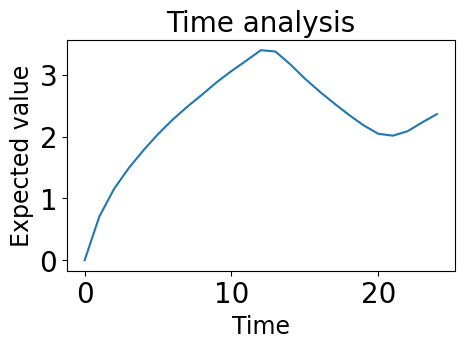

In [26]:
plt.figure(figsize=(5,3))
plt.plot(np.arange(prob_queue_arr.shape[0]), (np.arange(prob_queue_arr.shape[1])*prob_queue_arr).sum(axis=1))
plt.title('Time analysis', fontsize = 20)
plt.xlabel('Time', fontsize = 17)
plt.ylabel('Expected value', fontsize = 17)
plt.show()

In [ ]:
# phase 1:
max_num_customers = 100
time_dict = {}
for hour in range(sim_time+1):
    time_dict[hour] = np.zeros(max_num_customers)

In [ ]:
# phase 2:
for resultDictionary in list_of_sims:
    for hour in resultDictionary.keys():
        time_dict[hour][resultDictionary[hour]] += 1

In [ ]:
# phase 3: 
prob_queue_arr = np.array([])

for t in range(len(time_dict)):

    probs = (time_dict[t]/time_dict[t].sum())
    
    if t == 0:
        prob_queue_arr = np.array(probs).reshape(1, probs.shape[0])
    else:
        prob_queue_arr = np.concatenate((prob_queue_arr, np.array(probs).reshape(1,probs.shape[0])), axis = 0)

<div dir="rtl">

## לפי הגרף ניתן לראות מתי יש הכי הרבה עומס על המערכת. 
    
###  שאלה: נניח כי ההנהלה מאשרת להכפיל את קצב השירות למשך שעתיים ביום. באילו שעתיים זה יהיה? 
    
### ננסה כמה חלופות ונשווה את תוחלת מספר הצרכנים בכל חלופה. 
    
### נשווה בין 5 חלופות: 
    
### 1. בין השעות 0:00-02:00.
### 2. בין השעות 4:00-06:00.
### 3. בין השעות 10:00-12:00.
### 4. בין השעות 12:00-14:00.
### 5. בין השעות 20:00-22:00.
    

<div dir="rtl">

### חלופה 1:


In [ ]:
list_of_sims_1[0]

In [ ]:
sim_time = 24 

dict_sch_arrival = {0:1, 12:0.5,20:0.9}
dict_sch_service = {0:2, 2:1}
arrival_scd_pd = convert_dict_to_pd(dict_sch_arrival)
mu_schedule =  convert_dict_to_pd(dict_sch_service)

list_of_sims_1 = []
for ind in tqdm(range(10000)):
    list_of_sims_1.append(single_sim_rate_arrival_service(arrival_scd_pd, mu_schedule, sim_time)[0])
    
dist_option_1 = give_num_cust_dist(sim_time, list_of_sims_1)


<div dir="rtl">

### חלופה 2:


In [ ]:
sim_time = 24 

dict_sch_arrival = {0:1, 12:0.5,20:0.9}
dict_sch_service = {0:1, 4:2, 6:1}
arrival_scd_pd = convert_dict_to_pd(dict_sch_arrival)
mu_schedule =  convert_dict_to_pd(dict_sch_service)

list_of_sims_2 = []
for ind in tqdm(range(10000)):
    list_of_sims_2.append(single_sim_rate_arrival_service(arrival_scd_pd, mu_schedule, sim_time)[0])
    
dist_option_2 = give_num_cust_dist(sim_time, list_of_sims_2)


<div dir="rtl">

### חלופה 3:


In [ ]:
sim_time = 24 

dict_sch_arrival = {0:1, 12:0.5,20:0.9}
dict_sch_service = {0:1, 10:2, 12:1}
arrival_scd_pd = convert_dict_to_pd(dict_sch_arrival)
mu_schedule =  convert_dict_to_pd(dict_sch_service)

list_of_sims_3 = []
for ind in tqdm(range(10000)):
    list_of_sims_3.append(single_sim_rate_arrival_service(arrival_scd_pd, mu_schedule, sim_time)[0])
    
dist_option_3 = give_num_cust_dist(sim_time, list_of_sims_3)


<div dir="rtl">

### חלופה 4:


In [ ]:
sim_time = 24 

dict_sch_arrival = {0:1, 12:0.5,20:0.9}
dict_sch_service = {0:1, 12:2, 14:1}
arrival_scd_pd = convert_dict_to_pd(dict_sch_arrival)
mu_schedule =  convert_dict_to_pd(dict_sch_service)

list_of_sims_4 = []
for ind in tqdm(range(10000)):
    list_of_sims_4.append(single_sim_rate_arrival_service(arrival_scd_pd, mu_schedule, sim_time)[0])
    
dist_option_4 = give_num_cust_dist(sim_time, list_of_sims_4)


<div dir="rtl">

### חלופה 5:


In [ ]:
sim_time = 24 

dict_sch_arrival = {0:1, 12:0.5,20:0.9}
dict_sch_service = {0:1, 20:2, 22:1}
arrival_scd_pd = convert_dict_to_pd(dict_sch_arrival)
mu_schedule =  convert_dict_to_pd(dict_sch_service)

list_of_sims_5 = []
for ind in tqdm(range(10000)):
    list_of_sims_5.append(single_sim_rate_arrival_service(arrival_scd_pd, mu_schedule, sim_time)[0])
    
dist_option_5 = give_num_cust_dist(sim_time, list_of_sims_5)


In [ ]:
plt.figure(figsize=(10,6))

plt.plot(np.arange(prob_queue_arr.shape[0]), (np.arange(prob_queue_arr.shape[1])*prob_queue_arr).sum(axis=1), label = 'original')
plt.plot(np.arange(dist_option_1.shape[0]), (np.arange(dist_option_1.shape[1])*dist_option_1).sum(axis=1), label = 'option 1')
plt.plot(np.arange(dist_option_2.shape[0]), (np.arange(dist_option_2.shape[1])*dist_option_2).sum(axis=1), label = 'option 2')
plt.plot(np.arange(dist_option_3.shape[0]), (np.arange(dist_option_3.shape[1])*dist_option_3).sum(axis=1), label = 'option 3')
plt.plot(np.arange(dist_option_4.shape[0]), (np.arange(dist_option_4.shape[1])*dist_option_4).sum(axis=1), label = 'option 4')
plt.plot(np.arange(dist_option_5.shape[0]), (np.arange(dist_option_5.shape[1])*dist_option_5).sum(axis=1), label = 'option 5')

plt.legend()
plt.title('Time analysis', fontsize = 20)
plt.xlabel('Time', fontsize = 17)
plt.ylabel('Expected value', fontsize = 17)
plt.show()

In [ ]:
avg_1 = (np.arange(dist_option_1.shape[1])*dist_option_1).sum(axis=1).mean()
avg_2 = (np.arange(dist_option_2.shape[1])*dist_option_2).sum(axis=1).mean()
avg_3 = (np.arange(dist_option_3.shape[1])*dist_option_3).sum(axis=1).mean()
avg_4 = (np.arange(dist_option_4.shape[1])*dist_option_4).sum(axis=1).mean()
avg_5 = (np.arange(dist_option_5.shape[1])*dist_option_5).sum(axis=1).mean()


In [ ]:
avg_1, avg_2, avg_3, avg_4, avg_5

In [ ]:
## Plotting the graph

fig, (ax1) = plt.subplots(1, 1, figsize=(15, 6))
width = 0.25
max_probs = 11
rects1 = ax1.bar(np.arange(1,6),[avg_1, avg_2, avg_3, avg_4, avg_5], width)
plt.rcParams['font.size'] = '20'

# # Add some text for labels, title and custom x-axis tick labels, etc.
ax1.set_ylabel('Average number of customers', fontsize=21)
ax1.set_xlabel('Option', fontsize=20)
ax1.set_title( 'Compering different alternatives' , fontsize=21, fontweight="bold")
ax1.set_xticks(np.linspace(1,5,16).astype(int))
ax1.set_xticklabels(np.linspace(1,5,16).astype(int), fontsize=19)
ax1.legend(fontsize=22)
plt.show()

<div dir="rtl">

### החלופה השנייה הייתה הכי טובה

### כלומר הכי כדאי להכפיל קצב שירות בין 04:00-06:00
    
### מה הסיבות לכך? האם התוצאה הזאת מפתיעה?